# **Lab 7(A) - Laplacian Filter**

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

plt.rc('text', usetex=False)


## Apply Laplacian Filter on Image to get Sharp Image

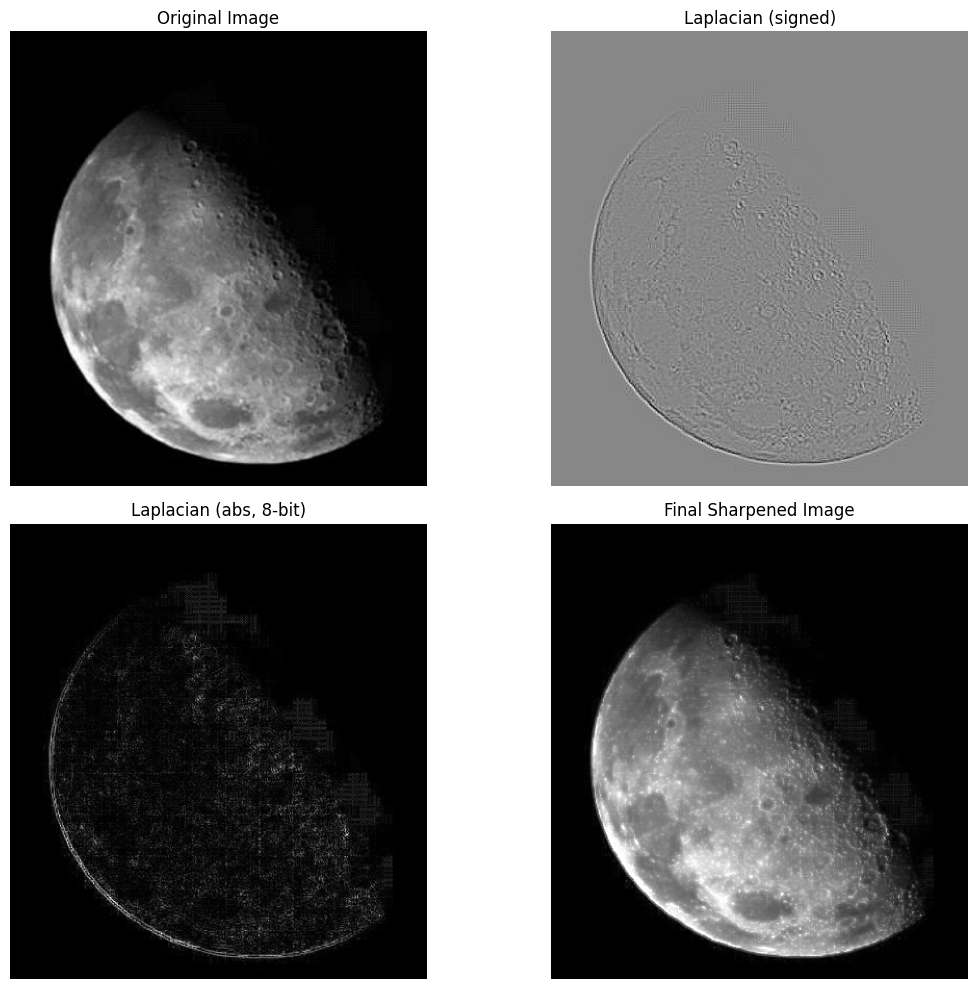

In [6]:
# ================ ( Laplacian Filter — Manual Kernel ) ===================

# 0. Image file path
imgFile = "moon.jpg"

# 1. Load image in grayscale
img = cv2.imread(imgFile, 0)
assert img is not None, f"Could not load image: {imgFile}"

# 2. Manually define the standard 4-neighbor Laplacian kernel
manual_kernel = np.array([
    [0,  1,  0],
    [1, -4,  1],
    [0,  1,  0]
], dtype=np.float32)

# 3. Apply filter — MUST use CV_64F to keep negative values
laplacian_manual = cv2.filter2D(img, cv2.CV_64F, manual_kernel)

# 4. Take absolute value and convert back to 8-bit for display
laplacian_abs = cv2.convertScaleAbs(laplacian_manual)

# 5. Sharpened = Original + |Laplacian|
finalImage = cv2.add(img, laplacian_abs)

# 6. Display results
plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(img, cmap='gray'),              plt.title('Original Image'),          plt.axis('off')
plt.subplot(222), plt.imshow(laplacian_manual, cmap='gray'), plt.title('Laplacian (signed)'),      plt.axis('off')
plt.subplot(223), plt.imshow(laplacian_abs, cmap='gray'),    plt.title('Laplacian (abs, 8-bit)'),  plt.axis('off')
plt.subplot(224), plt.imshow(finalImage, cmap='gray'),       plt.title('Final Sharpened Image'),   plt.axis('off')
plt.tight_layout()
plt.show()

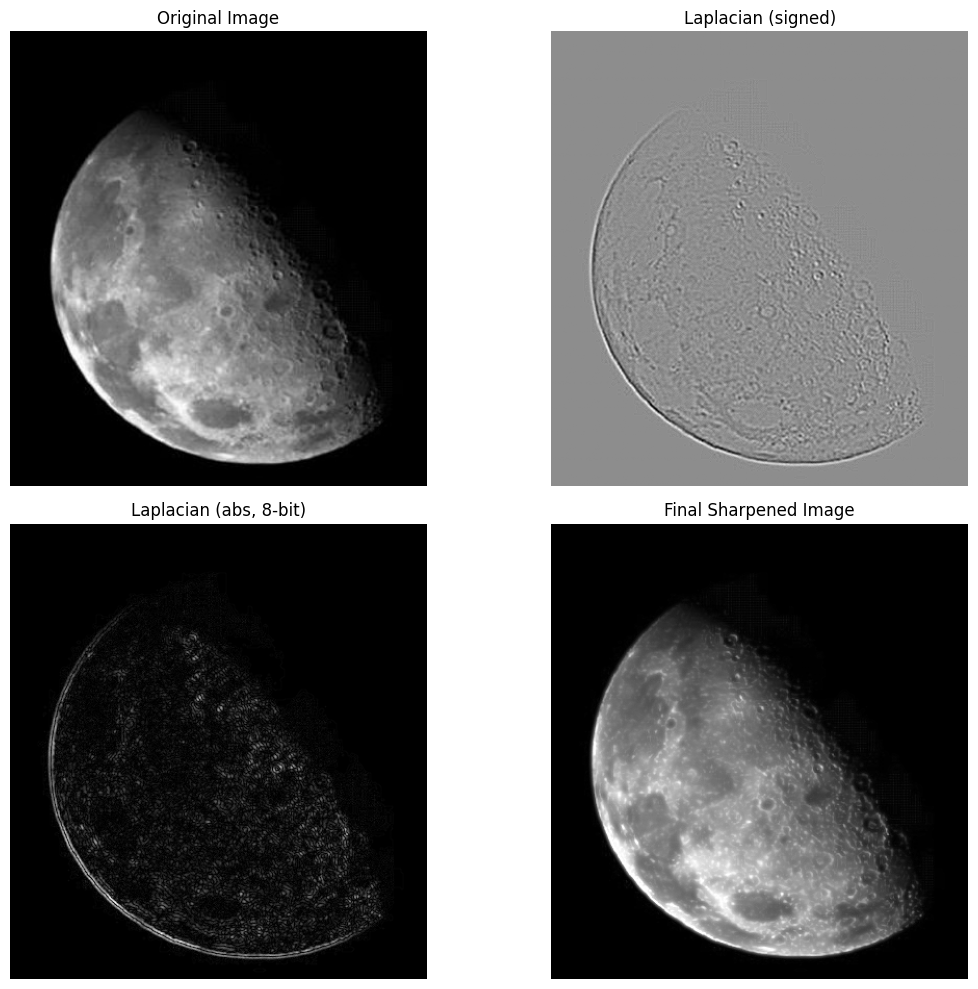

In [7]:
# ================== ( Laplacian Filter — Built-in + Gaussian Blur ) ===============

# 1. Gaussian blur first — the Laplacian amplifies noise
blurred = cv2.GaussianBlur(img, (3, 3), 0)

# 2. Apply built-in Laplacian (same as filter2D + 4-neighbor kernel)
laplacian = cv2.Laplacian(blurred, cv2.CV_64F)

# 3. Convert to 8-bit for visualization
laplacian_8bit = cv2.convertScaleAbs(laplacian)

# 4. Sharpened = Original + |Laplacian|
finalImage2 = cv2.add(img, laplacian_8bit)

# 5. Display results
plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(img, cmap='gray'),            plt.title('Original Image'),          plt.axis('off')
plt.subplot(222), plt.imshow(laplacian, cmap='gray'),      plt.title('Laplacian (signed)'),       plt.axis('off')
plt.subplot(223), plt.imshow(laplacian_8bit, cmap='gray'), plt.title('Laplacian (abs, 8-bit)'),   plt.axis('off')
plt.subplot(224), plt.imshow(finalImage2, cmap='gray'),    plt.title('Final Sharpened Image'),    plt.axis('off')
plt.tight_layout()
plt.show()


## Observations

- The **Laplacian** is a **second-derivative** operator. It responds strongly 
  to rapid intensity changes (edges) and gives **zero** in smooth areas.
- Using `cv2.CV_64F` is essential — the Laplacian produces **negative** values 
  at edges, and clipping them early would lose edge information.
- `convertScaleAbs()` maps the signed Laplacian to a displayable 8-bit range 
  by taking the absolute value.
- The sharpened image is computed as **Original + |Laplacian|**, which 
  amplifies high-frequency content (edges) and produces a crisper image.
- The Laplacian is **extremely noise-sensitive** — a Gaussian blur must be 
  applied **before** computing it to obtain clean, meaningful edges.

## Kernel Comparison

- **4-neighbor kernel** `[[0,1,0],[1,-4,1],[0,1,0]]`
  → Detects **horizontal and vertical** edges only. Faster, less noise.
- **8-neighbor kernel** `[[1,1,1],[1,-8,1],[1,1,1]]`
  → Also detects **diagonal** edges. Stronger response but picks up more noise.

## 4-neighbor vs 8-neighbor Comparison

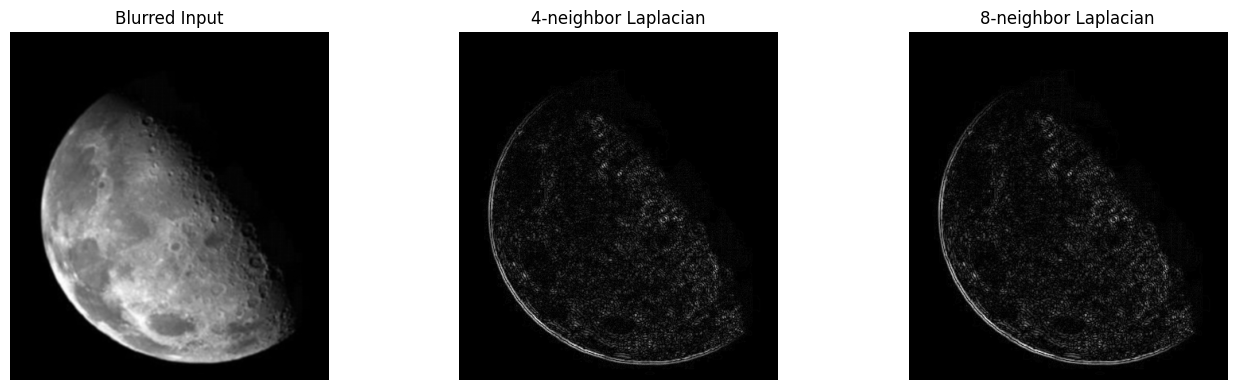

In [8]:
# ================== ( Compare 4-neighbor vs 8-neighbor Laplacian ) ===============

kernel_4 = np.array([[0,  1, 0],
                     [1, -4, 1],
                     [0,  1, 0]], dtype=np.float32)

kernel_8 = np.array([[1,  1, 1],
                     [1, -8, 1],
                     [1,  1, 1]], dtype=np.float32)

lap_4 = cv2.convertScaleAbs(cv2.filter2D(blurred, cv2.CV_64F, kernel_4))
lap_8 = cv2.convertScaleAbs(cv2.filter2D(blurred, cv2.CV_64F, kernel_8))

plt.figure(figsize=(14, 4))
plt.subplot(131), plt.imshow(blurred, cmap='gray'), plt.title('Blurred Input'),        plt.axis('off')
plt.subplot(132), plt.imshow(lap_4,   cmap='gray'), plt.title('4-neighbor Laplacian'),  plt.axis('off')
plt.subplot(133), plt.imshow(lap_8,   cmap='gray'), plt.title('8-neighbor Laplacian'),  plt.axis('off')
plt.tight_layout()
plt.show()

## Conclusion

- Laplacian filtering is a fast, kernel-based method to **sharpen edges**.
- **Blur before differentiating** — standard pipeline is 
  `Gaussian → Laplacian → |·| → add to original`.
- The **8-neighbor kernel** gives a stronger edge response (straight + diagonal) 
  but is noisier; the **4-neighbor kernel** is more robust in low-noise conditions.
- The final sharpened image (`Original + |Laplacian|`) preserves overall 
  brightness while enhancing local detail.